# 모의고사 20회 | 온도 지연값·전력 군집·비용 회귀 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys

FOLDER = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(FOLDER.parent / "공통"))
from researched_core import ResearchContext

ctx = ResearchContext(FOLDER)

## 1. 온도 1-step 예측과 지연값 검증

**상황을 이해하기**

기상 운영자는 매일 전날까지의 관측으로 오늘 온도를 예측한다.

**관측 단위와 판단 목적**

한 행은 하루이며 예측 시점에 당일 target/audit는 알 수 없다. 지연 무결성·시간 분리·경험 구간 한계를 확인한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `date` | 일별 날짜 |
| `target` | 당일 온도(도); 예측 반응 |
| `lag1` | 제공 전일 온도; 원 target과 검산 |
| `lag2` | 제공 전전일 온도; 검산 |
| `audit` | 당일 반응으로 만든 사후 값; 예측 입력 금지 |

**고정 분석 조건**

등간격 일별240행. target은 당일 온도(도), lag1/lag2는 제공된 과거값이나 오류가 각각1건 있다. target.shift(1/2)로 재구성하고 최초2행을 버린다. audit는 당일 target으로 만든 사후 점수이며 입력에서 제외한다. 입력은 lag1,lag2와 day-of-year의 sin/cos이다. 유효 자료 앞70%가 학습, 그 뒤가 최종평가다. 후보 RF60나무 깊이3/5, SVR RBF C=1/10,epsilon0.1. 학습 앞80% proper-fit, 뒤20% calibration을 먼저 분리한다. proper-fit 안의3-fold TimeSeriesSplit(gap2) CV RMSE 최소로 선택한다. calibration 절대잔차의 ceil((m+1)×0.9)번째 순위값(상한m)을 구간 반폭으로 쓴다. 최종 기간은 매일 전날 실제값이 공개되는1-step 운영이다.

### 1-1

**문제 (10점)**

날짜·target·제공lag1/lag2를 점검하고 원 target의 shift와 다른 지연값 위치를 찾으시오. 지연값을 다시 만들고 사후 audit 열을 입력에서 제외하시오.

**풀이 근거와 읽는 순서**

당일 예측은 전날까지 실제값을 안다는 1-step rolling 운영 가정이다.

여러 날 동시 예측과 구분한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [2]:
ctx.run("1-1", "lag_1")

,metric,value
0,lag1,[25]
1,lag2,[97]


excluded_features: ['date', 'target', 'audit']
valid_rows: 238
training_end: 165
test_start: 166
proper_end: 131
calibration_start: 132
conclusion: 오류 지연값2건을 원 target의 과거값으로 재구성했다. calibration과 최종평가는 후보 선택에 사용하지 않는다.


### 1-2

**문제 (10점)**

시간순 앞70%의 앞80% proper 학습 구간 안에서 gap2의 TimeSeriesSplit 3개로 RF와 SVR의 지정 후보를 비교하시오. 학습 폴드에서만 대치·스케일을 적합하고 CV RMSE로 선택하시오.

**풀이 근거와 읽는 순서**

무작위 분할은 미래를 섞는다.

fold의 검증 시작이 학습 끝+gap 뒤인지 확인하고 마지막30%는 선택에 쓰지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [3]:
ctx.run("1-2", "lag_2")

,candidate,cv_rmse,parameters
0,forest,1.686541,{'model__max_depth': 5}
1,svr,2.459881,{'model__C': 10}


selected: forest
conclusion: proper 학습 구간의 시간 CV에서 forest 선택. calibration과 최종 기간은 탐색에서 제외했다.


### 1-3

**문제 (10점)**

학습 마지막20%를 별도 calibration으로 떼고 앞부분만 적합한 선택 후보의 절대 잔차 90% 유한표본 분위수로 구간 반폭을 정하시오. 시간 의존성 아래 보장 한계를 명시하시오.

**풀이 근거와 읽는 순서**

시간순 calibration 잔차의 경험적 범위를 사용할 뿐 교환가능성 보장이나 정규 예측구간으로 부르지 않는다.

최종평가 잔차로 폭을 정하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [4]:
ctx.run("1-3", "lag_3")

calibration_size: 34
quantile_rank: 32
half_width: 2.145207304706421
calibration_residuals: [0.19050185495649785, 0.626272514168523, 1.857465428369668, 0.26356835577650983, 0.39890622020500643, 0.8123655788833553, 1.2380306377382837, 2.104927046772204, 0.722412468180611, 1.3104119543717907, 0.20234808115603897, 1.260035882566239, 2.3695930650729444, 0.3448856241203977, 1.7348014317640583, 0.8858584980359971, 1.453496484553174, 0.22752958220917563, 1.228168977566881, 0.29952444908068543, 0.6692821828048601, 0.6249834893359143, 1.8117638460540277, 2.795526694974395, 0.5193727466473348, 1.8134278594173558, 0.38391320404038964, 1.6520008973344815, 0.4042538543687897, 2.145207304706421, 1.6288744780303475, 1.651755858994612, 1.344660468955805, 1.339779199557146]
proper_end: 131
calibration_start: 132
calibration_end: 165
conclusion: 시간순 calibration 절대잔차 경험 반폭 2.1452. 시간 의존성 때문에 교환가능성 기반 보장을 주장하지 않는다.


### 1-4

**문제 (10점)**

같은 최종30%의 매일 1-step 예측을 수행하여 원단위 RMSE·MAE·R²·경험 구간 포함률·평균 폭을 구하시오. 선택 모형은 calibration 후 다시 적합하지 말고 naive lag1과 비교하시오.

**풀이 근거와 읽는 순서**

평가 중 직전 실제값이 공개되는 운영을 명시한다.

미래 다단계 예측으로 성능을 표시하지 않으며 구간을 유지하려면 선택 모형의 재적합을 하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

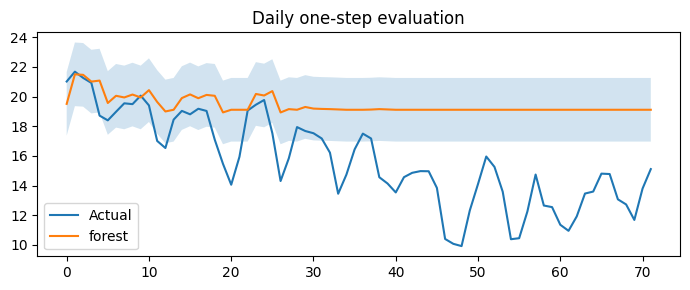

,metric,value
0,rmse,4.586348
1,mae,3.794198
2,r2,-1.291370


,metric,value
0,rmse,1.501069
1,mae,1.170860
2,r2,0.754550


coverage: 0.3333333333333333
mean_width: 4.290414609412842
baseline_predictions: [18.1885992222, 21.0167780352, 21.6798378533, 21.2604134716, 20.9233301294, 18.7165860646, 18.397669959, 18.9776285159, 19.5471115412, 19.4910490457, 20.0654893148, 19.4048017794, 17.0110193527, 16.5330616351, 18.4470014821, 19.0358171358, 18.8052561415, 19.1803838475, 19.0319812274, 17.0942252253, 15.4651997511, 14.0585003487, 15.9402071743, 19.0608054482, 19.4521317924, 19.7707514219, 17.5285437041, 14.3082703595, 15.8381463071, 17.9447109775, 17.6792038432, 17.5303200433, 17.1758274738, 16.220494015, 13.4512703211, 14.7381917098, 16.4421399006, 17.5030609723, 17.1758141361, 14.5643350147, 14.1407612855, 13.5388201947, 14.5678808534, 14.8613425974, 14.975574619, 14.9662751615, 13.8448339135, 10.4003835921, 10.0727321224, 9.92044191934, 12.3231707955, 14.1092876408, 15.9602380763, 15.258634428, 13.5890041979, 10.3845653623, 10.4523913217, 12.2543581176, 14.7442380612, 12.6556816807, 12.5483028166, 11.3583

In [5]:
ctx.run("1-4", "lag_4")

## 2. 전력량 집계와 군집별 사용 패턴

**상황을 이해하기**

전력 운영팀이 가구별 시간대 사용 패턴을 탐색한다.

**관측 단위와 판단 목적**

한 행은 한 가구의 한 시간 사용량이다. 가구 프로필 군집과 원 관측 집계를 분리해 설명한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `household` | 가상 가구 식별자 |
| `timestamp` | 시간별 기록 시점 |
| `kwh` | 해당1시간의 사용 전력량(kWh); 전력kW 아님 |

**고정 분석 조건**

가상12가구×14일×24시간의 등간격 전력량이다. key는 household/timestamp. 가구별 시간대 평균24열 각각을 가구 간 평균/표준편차(ddof0)로 표준화하고 KMeans k=2/3/4,n_init10,seed=20281020로 비교한다. silhouette 최대 선택, 동률은 작은k다. 그 라벨을 many-to-one으로 원 관측에 연결한다. 군집×요일(월0)×시간 평균 kWh 히트맵은 공통색범위를 쓴다. 원 후기의15분 자료 대신1시간 간격으로 새로 설계했다.

### 2-1

**문제 (8점)**

household×timestamp key·시간 간격·전력량 단위를 점검하시오. 하루/가구별 총 kWh와 시간대 평균 프로필을 각각 만들어 집계 분모를 설명하시오.

**풀이 근거와 읽는 순서**

자료는 학습용 시간별 전력량이며 원 후기에 나온15분 간격과 구분한다.

kWh를 전력 kW와 혼동하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [6]:
ctx.run("2-1", "energy_1")

observations: 4032
households: 12
household_days: 168
total_kwh: 3100.598015508007
daily_mean_kwh: 18.45594056850004
conclusion: 시간 전력량을 일별로 합산했다. 1시간 평균 프로필은 같은 시간대14일의 평균이며 일별 합과 다르다.


### 2-2

**문제 (7점)**

가구별24차원 평균 프로필의 시간열을 가구 간 표준화하고 k=2·3·4 KMeans를 비교해 silhouette 최대로 선택하시오. 이 자료 전체가 탐색 모집단이며 예측 평가가 아님을 설명하시오.

**풀이 근거와 읽는 순서**

계수·스케일·k를 사전 정의하고 silhouette는 같은 변환 공간에서 계산한다.

군집 번호는 순서나 우열을 뜻하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [7]:
ctx.run("2-2", "energy_2")

,k,silhouette,inertia
0,2,0.275278,166.060192
1,3,0.258755,120.561419
2,4,0.259431,92.282974


selected_k: 2


,household,cluster
0,H01,1
1,H02,1
2,H03,1
3,H04,1
4,H05,1
5,H06,1
6,H07,0
7,H08,0
8,H09,0
9,H10,0


conclusion: 같은 표준화 공간의 silhouette로 k=2를 골랐다. 전체 자료의 탐색이며 새 가구 예측 성능이 아니다.


### 2-3

**문제 (8점)**

가구별 군집을 원 관측에 many-to-one으로 연결하고 군집×요일×시간 평균 히트맵을 ax별로 제시하시오. 라벨 결합으로 행 수가 늘거나 빠지지 않는지 검증하시오.

**풀이 근거와 읽는 순서**

요일0은 월요일이다.

하루 합과 시간별 평균을 같은 값으로 취급하지 않는다.

서로 다른 군집에 같은 색 범위를 쓴다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

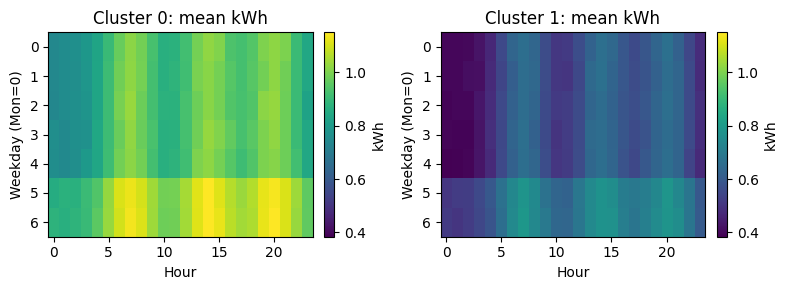

rows_before: 4032
rows_after: 4032
missing_labels: 0
common_vmin: 0.383246800013
common_vmax: 1.1507605603219166
conclusion: 라벨 연결 전후4032행으로 같다. 모든 군집 히트맵에 같은 색 범위를 적용했다.


In [8]:
ctx.run("2-3", "energy_3")

### 2-4

**문제 (7점)**

군집별 가구 수·일평균 사용량·피크 시간·야간 비율을 비교하고 수요관리 제안을 하시오. 집계 평균의 한계와 실험/미래 운영 검증 필요성을 제시하시오.

**풀이 근거와 읽는 순서**

관측된 군집 차이는 요금정책의 인과 효과가 아니다.

프로필 평균과 실제 개별 피크의 차이를 명시한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [9]:
ctx.run("2-4", "energy_4")

,cluster,households,mean_daily_kwh,peak_hour,night_fraction
0,0,6,22.774198,20,0.219410
1,1,6,14.137683,7,0.200773


conclusion: 피크·야간 비율은 집단 평균 패턴이다. 절감 효과는 가구 수준 실험과 미래 운영 자료에서 별도로 검증해야 한다.


## 3. 배송비 설명과 예측

**상황을 이해하기**

관측의 조건과 결과 관계를 설명하고 새 관측의 결과를 예측한다.

**관측 단위와 판단 목적**

한 행은 서로 독립인 관측이다. x1=거리 편차지수, x2=화물량 편차지수, x3=취급 점수, target=배송비(천원). 추론의 조건과 예측 성능을 구분해 보고한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 독립 관측 식별자; 입력 제외 |
| `x1` | 거리 편차지수 |
| `x2` | 화물량 편차지수 |
| `x3` | 취급 점수 |
| `group` | 관측 집단 범주 A/B; 처치 아님 |
| `target` | 배송비(천원) |

**고정 분석 조건**

x1=거리 편차지수, x2=화물량 편차지수, x3=취급 점수, target=배송비(천원). 240행. x1에 결측이 있다. id를 제외하고 중앙값 대치 후 수치형은 학습 평균/표준편차(ddof0)로 표준화하고 집단은 one-hot(drop first) 처리한 뒤 OLS를 적합한다. x1,x2,x3의 단순/전체모형 비교는 같은 학습 행이다. random_state=20281020로 학습70%/평가30%를 나누고 학습3-fold shuffled CV를 사용한다. 다항식 차수2, RF60나무 깊이3/5는 사전 후보다.

### 3-1

**문제 (8점)**

관측 단위·입력·반응·누출 위험과 결측을 정리하고 지정한 학습/평가 원행을 기록하시오. 학습 입력의 분포와 변수 관계를 ax 두 개에 제시하시오.

**풀이 근거와 읽는 순서**

식별자·사후 반응은 제외하고 대치는 학습 자료에서만 추정한다.

평가 설계를 먼저 고정한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

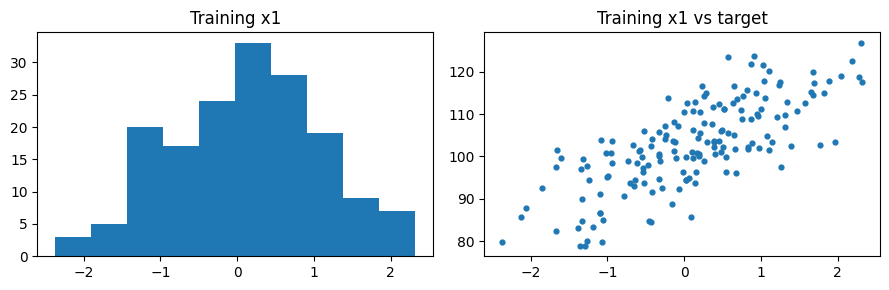

n: 240


,metric,value
0,x1,3
1,x2,0
2,x3,0
3,group,0


conclusion: 학습 168행·봉인 평가 72행. 실제값으로 만든 파생변수는 사용하지 않는다.


In [10]:
ctx.run("3-1", "reg_1")

### 3-2

**문제 (7점)**

학습 자료에 지정 OLS를 적합하고 계수 t 검정·전체 F 검정·R²·수정 R²·AIC·BIC를 보고하시오. 단순모형과 전체모형의 비교에서 같은 행과 반응을 유지하시오.

**풀이 근거와 읽는 순서**

t는 조건부 계수, F는 전체 설명항의 검정이다.

학습 R²와 예측 성능을 구분하며 같은 반응·행에서만 정보량을 비교한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [11]:
ctx.run("3-2", "reg_2")

coefficient_scale: 수치형은 학습 표준편차1단위, 범주는 B−A. 교호작용은 표준화 좌표의 곱.


,term,coefficient,standard_error,t_statistic,p_value,ci_lower,ci_upper,reject_h0
0,Intercept,100.603243,0.309700,324.840666,4.284442e-231,99.991701,101.214785,True
1,numeric__x1,8.078801,0.227028,35.585103,9.373015e-79,7.630507,8.527096,True
2,numeric__x2,-4.638605,0.230858,-20.092877,5.771497e-46,-5.094463,-4.182747,True
3,numeric__x3,2.814691,0.230875,12.191416,1.034488e-24,2.358800,3.270582,True
4,category__group_B,4.892234,0.455061,10.750719,1.029693e-20,3.993659,5.790808,True


,metric,value
0,r2,0.921859
1,adjusted_r2,0.919942
2,r2_kind,centered
3,f_statistic,480.743931
4,f_p_value,0.0
5,f_kind,classical overall F
6,df_model,4.0
7,df_resid,163.0
8,n_samples,168
9,aic,843.463005


,metric,value
0,r2,0.545055
1,adjusted_r2,0.542314
2,r2_kind,centered
3,f_statistic,198.879146
4,f_p_value,0.0
5,f_kind,classical overall F
6,df_model,1.0
7,df_resid,166.0
8,n_samples,168
9,aic,1133.422455


,test,statistic,p_value,reject_h0,df_num,df_den
0,nested-model F,262.001517,4.126396e-62,True,3.0,163.0


conclusion: 학습 R² 0.9219는 봉인 평가 성능이 아니다. 계수 t·F는 사전 OLS 사양과 추론 가정에 조건부다.


### 3-3

**문제 (8점)**

RESET·잔차 정규성·Breusch-Pagan·VIF·Cook을 계산하고 Q-Q·잔차/적합값을 subplots로 제시하시오. 명시하지 않은 관측 제거를 수행하지 말고 진단별 한계를 설명하시오.

**풀이 근거와 읽는 순서**

정규성은 y가 아니라 잔차를 대상으로 한다.

VIF는 변수의 공선성, Cook은 관측 영향력이다.

비기각을 가정 증명으로 쓰지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

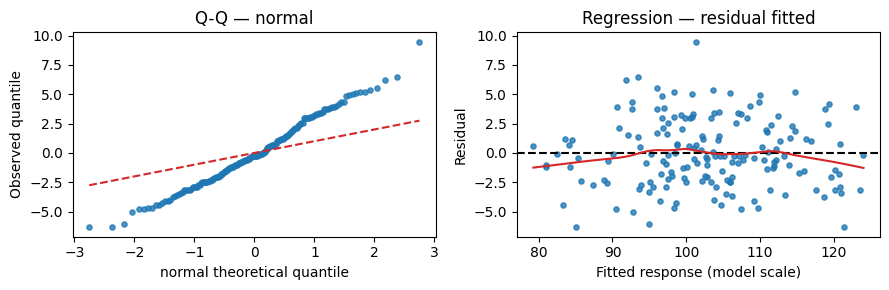

,test,statistic,p_value,reject_h0,df_num,df_den
0,jarque_bera,2.524557,0.283008,False,None,None


,test,statistic,p_value,reject_h0,df_num,df_den
0,RESET F,1.786105,0.170917,False,2.0,161.0


,test,statistic,p_value,reject_h0,df_num,df_den
0,breusch_pagan LM,2.445237,0.654468,False,None,None
1,breusch_pagan F,0.601876,0.661815,False,None,None


,feature,vif,tolerance,flag
0,numeric__x1,1.005184,0.994843,False
1,numeric__x2,1.039390,0.962102,False
2,numeric__x3,1.039541,0.961963,False
3,category__group_B,1.004491,0.995529,False


,position,row_label,residual,studentized_internal,studentized_external,leverage,cooks_distance,dffits,outlier_p,adjusted_outlier_p,cook_flag,leverage_flag,studentized_flag,outlier_reject,original_position
29,29,29,-6.347901,-2.205411,-2.232192,0.038255,0.038693,-0.445189,0.026974,1.0,True,False,False,False,181
145,145,145,6.475433,2.247977,2.276639,0.036764,0.038574,0.444771,0.024117,1.0,True,False,False,False,32
128,128,128,-5.062735,-1.776813,-1.788762,0.057534,0.038545,-0.441957,0.075522,1.0,True,False,False,False,163
127,127,127,5.156154,1.803651,1.816326,0.051307,0.035187,0.422395,0.071169,1.0,True,False,False,False,222
17,17,17,-4.764185,-1.671796,-1.681136,0.057266,0.033955,-0.414338,0.094664,1.0,True,False,False,False,7


removed_rows: 0
conclusion: 본 풀이에서는 영향 관측을 삭제하지 않는다. 진단은 사양 점검이며 비기각을 가정의 증명으로 읽지 않는다.


In [12]:
ctx.run("3-3", "reg_3")

### 3-4

**문제 (7점)**

동일 학습 CV에서 기준 선형모형·다항식·랜덤포레스트를 RMSE로 비교해 하나를 선택하시오. 봉인한 같은 평가 행에서 원단위 RMSE·MAE·R²와 관측-예측 그림을 제시하고 기준 대비 차이를 해석하시오.

**풀이 근거와 읽는 순서**

전처리를 CV 안에서 적합한다.

설명용 OLS 진단과 선택한 예측모형의 적용 조건을 구분하고 최종평가로 다시 고르지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

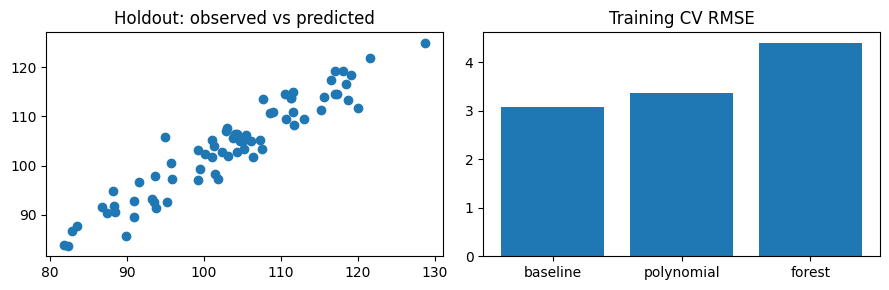

,candidate,cv_rmse,parameters
0,baseline,3.076503,{}
1,polynomial,3.357694,{}
2,forest,4.399173,{'model__max_depth': 5}


selected: baseline


,metric,value
0,rmse,3.340169
1,mae,2.720208
2,r2,0.901413


,metric,value
0,rmse,3.340169
1,mae,2.720208
2,r2,0.901413


delta_r2: 0.0
baseline_predictions: [94.8318685484185, 97.21917009871923, 113.6592880467893, 105.12513161867864, 110.90243282750427, 105.20576355766387, 91.86690455095003, 90.29419580636784, 107.10179776155442, 105.8185505165697, 103.13861417425029, 102.81053815148415, 98.26941726353283, 105.05121398079991, 108.21415527667864, 105.17668286014008, 121.85130399261689, 105.5443041226667, 83.6500506533204, 90.56709898150217, 85.79004145378953, 109.3831814564615, 106.49746510379342, 103.90052830419134, 97.19761679126854, 99.23029961697468, 106.3183435708484, 103.40108096541837, 102.37114093127681, 114.57470616486461, 100.45309383391827, 92.58986839305837, 111.37436776834892, 125.02501360655319, 97.1076104410587, 101.85843113058841, 114.53807534151659, 105.04993883202067, 113.34115503700211, 113.77327824612858, 109.44924369595181, 83.79148066021727, 113.53467852349027, 107.68617487279067, 119.13657294739035, 117.38226970810044, 86.61987307013848, 119.15923278319842, 106.50736958813516, 114.8

In [13]:
ctx.run("3-4", "reg_4")